In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("../Dataset/cleaned_data.csv")
print("missing values are=",df["AQI"].isna().sum())

missing values are= 9139


Original total rows: 53686
Sensor first recording: 2017-10-17 02:00:00
Rows after cold start removal: 53686
Missing values to handle: 0
Missing values after cleaning: 0

=== CLEANING SUMMARY ===
Total rows: 53686
Date range: 2017-10-17 02:00:00 to 2023-12-31 23:00:00
Missing values remaining: 0

AQI Statistics:
count    53686.000000
mean       255.970050
std        135.827600
min          1.000000
25%        134.742221
50%        237.000000
75%        368.000000
max        500.000000
Name: AQI, dtype: float64


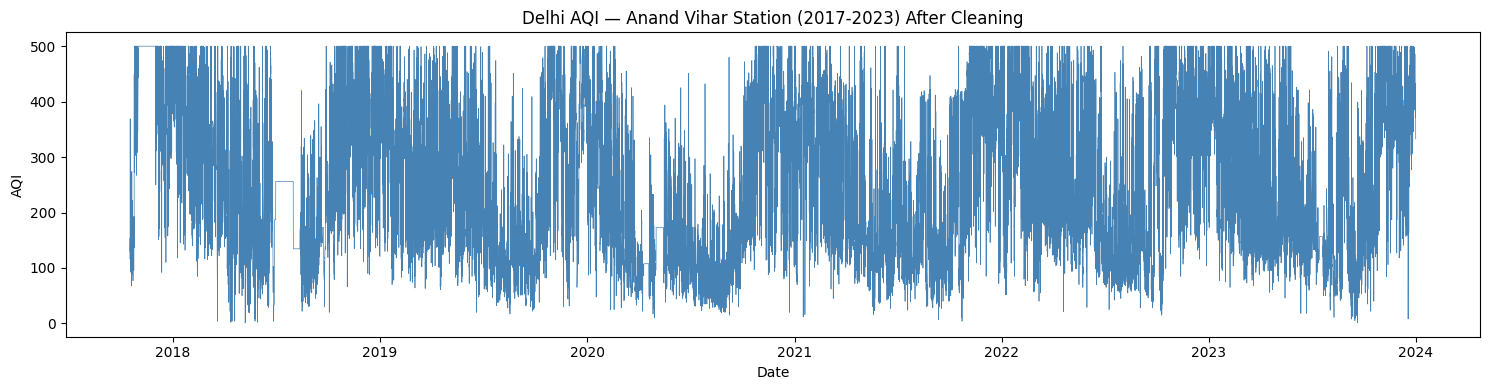


Saved as final_clean_aqi.csv


In [6]:
df['Datetime'] = pd.to_datetime(df['Datetime'])

# ── Step 2: Cold Start Fix ─────────────────────────────────────────────────
# Remove leading empty rows before sensor started recording
first_reading_row = df['AQI'].first_valid_index()
start_time = df.loc[first_reading_row, 'Datetime']

print(f"Original total rows: {len(df)}")
print(f"Sensor first recording: {start_time}")

df = df.loc[first_reading_row:].reset_index(drop=True)
print(f"Rows after cold start removal: {len(df)}")
print(f"Missing values to handle: {df['AQI'].isna().sum()}")

# ── Step 3: Layered Missing Value Strategy ─────────────────────────────────
# Layer 1: Forward fill short gaps up to 6 hours
# (sensor blips, brief outages)
df['AQI_Clean'] = df['AQI'].ffill(limit=6)

# Layer 2: Linear interpolation for medium gaps up to 24 hours
# (overnight outages, maintenance windows)
df['AQI_Clean'] = df['AQI_Clean'].interpolate(
    method='linear',
    limit=24,
    limit_direction='both'
)

# Layer 3: Monthly average for longer gaps
# (equipment failure lasting days)
df['YearMonth'] = df['Datetime'].dt.to_period('M')
monthly_avg = df.groupby('YearMonth')['AQI_Clean'].transform('mean')
df['AQI_Clean'] = df['AQI_Clean'].fillna(monthly_avg)

# Layer 4: Global mean as final fallback
df['AQI_Clean'] = df['AQI_Clean'].fillna(df['AQI_Clean'].mean())

print(f"Missing values after cleaning: {df['AQI_Clean'].isna().sum()}")

# ── Step 4: Finalize ───────────────────────────────────────────────────────
df = df.drop(columns=['AQI', 'YearMonth'])
df = df.rename(columns={'AQI_Clean': 'AQI'})

# ── Step 5: Verification ───────────────────────────────────────────────────
print("\n=== CLEANING SUMMARY ===")
print(f"Total rows: {len(df)}")
print(f"Date range: {df['Datetime'].min()} to {df['Datetime'].max()}")
print(f"Missing values remaining: {df['AQI'].isna().sum()}")
print(f"\nAQI Statistics:")
print(df['AQI'].describe())

# Overview plot
plt.figure(figsize=(15,4))
plt.plot(df['Datetime'], df['AQI'], linewidth=0.5, color='steelblue')
plt.title('Delhi AQI — Anand Vihar Station (2017-2023) After Cleaning')
plt.xlabel('Date')
plt.ylabel('AQI')
plt.tight_layout()
plt.show()

# Save
df.to_csv("../Dataset/final_clean_aqi.csv", index=False)
print("\nSaved as final_clean_aqi.csv")